In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(1)

city = "Київ"
base_temp = 9.5
amplitude = 14
base_consumption = 5200
k = 55
noise_sd = 80

months = np.arange(1, 13)

temp = base_temp + amplitude * np.cos((months - 7) / 12 * 2 * np.pi)
temp = np.round(temp + np.random.normal(0, 0.5, size=12), 1)

consumption = (
    base_consumption
    - k * (temp - base_temp)
    + np.random.normal(0, noise_sd, size=12)
)
consumption = np.round(consumption, 0)

city_data = pd.DataFrame({
    "місяць": months,
    "температура": temp,
    "споживання_МВтгод": consumption,
})

print("Практика 19. Варіант 1 — Київ")
display(city_data)

Практика 19. Варіант 1 — Київ


,місяць,температура,споживання_МВтгод
0,1,-3.7,5900.0
1,2,-2.9,5851.0
2,3,2.2,5692.0
3,4,9.0,5140.0
4,5,16.9,4779.0
5,6,20.5,4525.0
6,7,24.4,4384.0
7,8,21.2,4603.0
8,9,16.7,4716.0
9,10,9.4,5297.0


### Завдання 1. Класифікація математичної моделі

Модель описує залежність місячного споживання електроенергії від середньої температури повітря в Києві.

1. **За врахуванням випадковості — стохастична модель.** До розрахункового споживання додається випадкова похибка, тому результати можуть відрізнятися навіть за однакової температури.
2. **За зміною в часі — статична модель.** Споживання для кожного місяця обчислюється за його температурою. Попередні значення споживання не використовуються.
3. **За призначенням — описова та прогнозна модель.** Вона описує зв’язок між температурою та споживанням і дає змогу оцінювати споживання за відомою температурою.
4. **Це не балансова модель**, оскільки вона не описує рівність надходжень і витрат ресурсів.
5. **Це не оптимізаційна модель**, оскільки вона не шукає найкращого рішення за заданим критерієм.
6. **Це не імітаційна модель у вузькому значенні**, оскільки вона не відтворює послідовність процесів у часі, а використовує формулу залежності між двома величинами.

Отже, модель є статичною стохастичною статистичною моделлю, яку можна використовувати для опису залежності та прогнозування місячного споживання електроенергії.

In [2]:
b, a = np.polyfit(
    city_data["температура"],
    city_data["споживання_МВтгод"],
    1
)

city_data["передбачення"] = a + b * city_data["температура"]

print(f"Рівняння моделі: споживання = {a:.2f} + ({b:.2f}) × температура")
print(f"Вільний член a = {a:.2f}")
print(f"Коефіцієнт b = {b:.2f}")

display(city_data)

Рівняння моделі: споживання = 5739.14 + (-56.52) × температура
Вільний член a = 5739.14
Коефіцієнт b = -56.52


,місяць,температура,споживання_МВтгод,передбачення
0,1,-3.7,5900.0,5948.249384
1,2,-2.9,5851.0,5903.036223
2,3,2.2,5692.0,5614.802326
3,4,9.0,5140.0,5230.490462
4,5,16.9,4779.0,4784.010503
5,6,20.5,4525.0,4580.551281
6,7,24.4,4384.0,4360.137124
7,8,21.2,4603.0,4540.989765
8,9,16.7,4716.0,4795.313793
9,10,9.4,5297.0,5207.883882


In [3]:
residuals = (
    city_data["споживання_МВтгод"]
    - city_data["передбачення"]
)

city_data["залишок"] = residuals

ss_res = (residuals ** 2).sum()

ss_tot = (
    (
        city_data["споживання_МВтгод"]
        - city_data["споживання_МВтгод"].mean()
    ) ** 2
).sum()

r_squared = 1 - ss_res / ss_tot

print(f"Сума квадратів залишків: {ss_res:.2f}")
print(f"Загальна сума квадратів: {ss_tot:.2f}")
print(f"Коефіцієнт детермінації R²: {r_squared:.4f}")

display(city_data)

Сума квадратів залишків: 44943.18
Загальна сума квадратів: 3820146.00
Коефіцієнт детермінації R²: 0.9882


,місяць,температура,споживання_МВтгод,передбачення,залишок
0,1,-3.7,5900.0,5948.249384,-48.249384
1,2,-2.9,5851.0,5903.036223,-52.036223
2,3,2.2,5692.0,5614.802326,77.197674
3,4,9.0,5140.0,5230.490462,-90.490462
4,5,16.9,4779.0,4784.010503,-5.010503
5,6,20.5,4525.0,4580.551281,-55.551281
6,7,24.4,4384.0,4360.137124,23.862876
7,8,21.2,4603.0,4540.989765,62.010235
8,9,16.7,4716.0,4795.313793,-79.313793
9,10,9.4,5297.0,5207.883882,89.116118


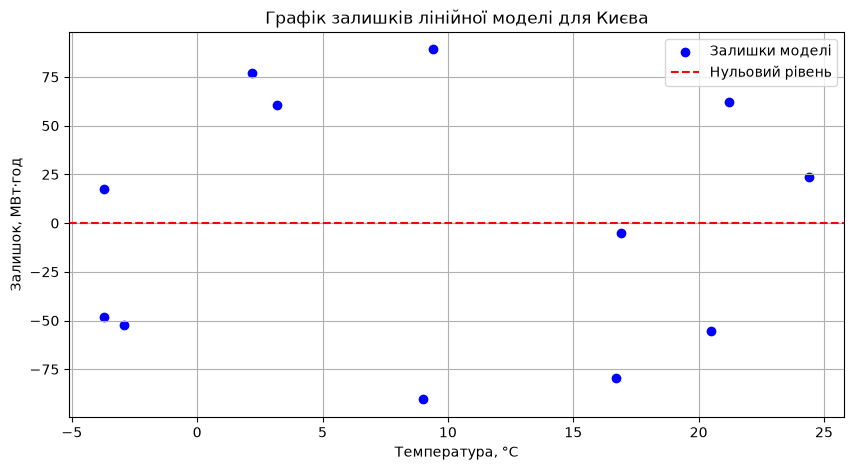

In [4]:
plt.figure(figsize=(10, 5))

plt.scatter(
    city_data["температура"],
    city_data["залишок"],
    color="blue",
    label="Залишки моделі"
)

plt.axhline(y=0, color="red", linestyle="--", label="Нульовий рівень")

plt.xlabel("Температура, °C")
plt.ylabel("Залишок, МВт·год")
plt.title("Графік залишків лінійної моделі для Києва")
plt.legend()
plt.grid(True)
plt.show()

### Завдання 4. Перевірка та валідація моделі

**Верифікація моделі** — це перевірка правильності реалізації обчислень. Для перевірки можна взяти перший місяць, підставити його температуру у рівняння лінійної моделі та порівняти результат із передбаченням, отриманим у програмі. Якщо результати збігаються з урахуванням округлення, обчислення реалізовано правильно.

**Валідація моделі** — це перевірка того, наскільки добре модель описує реальне споживання електроенергії. Для цього необхідно порівняти прогноз із фактичними даними, які не використовувалися під час побудови моделі, наприклад із даними за наступний рік. Оскільки модель побудована лише на 12 місячних спостереженнях, цих даних недостатньо для повноцінної незалежної валідації.

Отже, верифікація допомагає перевірити правильність обчислень, а валідація — відповідність моделі реальним умовам.

In [5]:
first_month = city_data.iloc[0]

temperature = first_month["температура"]
actual_prediction = first_month["передбачення"]
manual_prediction = a + b * temperature

print(f"Місяць: {int(first_month['місяць'])}")
print(f"Температура: {temperature:.1f} °C")
print(f"Передбачення з таблиці: {actual_prediction:.2f} МВт·год")
print(f"Ручний розрахунок: {manual_prediction:.2f} МВт·год")

if np.isclose(actual_prediction, manual_prediction):
    print("Верифікація пройдена: результати збігаються.")
else:
    print("Верифікація не пройдена: результати відрізняються.")

Місяць: 1
Температура: -3.7 °C
Передбачення з таблиці: 5948.25 МВт·год
Ручний розрахунок: 5948.25 МВт·год
Верифікація пройдена: результати збігаються.


### Завдання 5. Вдосконалення математичної моделі

Для оцінювання адекватності лінійної моделі потрібно враховувати коефіцієнт детермінації \(R^2\) та характер розподілу залишків. Високе значення \(R^2\) свідчить про те, що модель пояснює значну частину мінливості споживання електроенергії, але саме по собі не гарантує правильності прогнозів.

Якщо залишки розташовані хаотично навколо нуля, а коефіцієнт детермінації достатньо високий для поставленої задачі, лінійна модель може бути прийнятною. У такому випадку її не обов’язково ускладнювати, оскільки проста модель легша для пояснення та використання.

Якщо ж залишки демонструють закономірність, наприклад систематичне завищення або заниження прогнозів за певних температур, модель доцільно вдосконалити. Можна додати квадратичний член температури, щоб урахувати нелінійну залежність, або використати окремі залежності для опалювального сезону та теплих місяців. Також на споживання можуть впливати день тижня, кількість населення, опалення та використання кондиціонерів.

Для обґрунтованого вибору вдосконалення потрібно перевірити результати на додаткових даних. Модель слід ускладнювати лише тоді, коли це помітно покращує точність прогнозування.

### Контрольні запитання

**1. Чим відрізняються верифікація та валідація для цієї моделі?**

Верифікація перевіряє правильність реалізації рівняння \(y=a+bT\) у програмі, наприклад шляхом ручного розрахунку прогнозу для одного місяця. Валідація перевіряє, наскільки добре модель прогнозує реальне споживання на незалежних даних, які не використовувалися для її побудови.

**2. Як класифікувати модель за різними ознаками та чому це не суперечить одне одному?**

Модель є стохастичною, оскільки вихідні дані містять випадкову похибку, і статичною, оскільки прогноз залежить від температури відповідного місяця, а не від попереднього стану системи. За призначенням це описова та прогнозна статистична модель. Ці характеристики не суперечать одна одній, оскільки описують різні властивості моделі.

**3. Що показує \(R^2\)? Чи доводить високе значення, що модель правильна та безпечна для екстраполяції?**

Коефіцієнт \(R^2\) показує частку мінливості споживання, яку пояснює модель. Високе значення не доводить, що модель повністю правильна, не гарантує відсутності систематичних помилок і не забезпечує надійності прогнозів за межами температурного діапазону використаних даних. Для оцінювання також потрібно аналізувати залишки та перевіряти модель на незалежних даних.

**4. Чому структура залишків інформативніша за саму величину помилок?**

Загальна величина помилок показує, наскільки прогнози відрізняються від фактичних значень. Проте структура залишків допомагає виявити систематичні проблеми. Якщо залишки утворюють тренд або криву, це може свідчити про невраховану залежність. Якщо вони випадково розташовані навколо нуля, це є аргументом на користь адекватності обраної форми моделі.